# 02 — Exploratory Analysis and Visualisations

Descriptive statistics and the figures used in the report.

The charts are deliberately limited to those that inform a modelling decision: the distribution of the dependent variable and the case for the log transform, the correlation structure that anticipates collinearity, the functional and geographic differentials, the human-capital profiles, and the group contrasts. Figures are written to `report_charts/` and rendered inline at the end of the notebook.

> *One of three notebooks: `01_data_processing`, `02_eda_visualisations` and `03_hypothesis_regression`. Run them in order from the `notebooks/` directory.*

## Setup

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CLEAN = ROOT / "ITEmp_Cleaned.csv"
CHARTS = ROOT / "report_charts"
TABLES = ROOT / "output_tables"

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({"figure.dpi": 150, "savefig.bbox": "tight",
                     "axes.titlesize": 13, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 9})

DV = "sal"
BINARY_VARS = ["nonprev", "female", "married", "metro", "norcen", "south",
               "west", "itreq", "itprog", "itqual", "itarch", "itai",
               "itclient", "itrd", "ittech", "wrkhm"]
CONTINUOUS_VARS = ["sal", "edu", "exper", "ten", "dep", "momed", "daded", "sib"]
NUMERIC = CONTINUOUS_VARS + BINARY_VARS


def load() -> pd.DataFrame:
    return pd.read_csv(CLEAN)


def save(fig, name: str) -> None:
    CHARTS.mkdir(parents=True, exist_ok=True)
    path = CHARTS / name
    fig.savefig(path)
    plt.close(fig)
    print(f"  wrote {path.relative_to(ROOT)}")

## descriptives

Standard descriptive statistics plus two tables the report draws on: per-variable summaries, and mean salary by group (gender, marital status, privilege, location, work mode, AI exposure, R&D, tech support, architecture).

In [2]:
def descriptive_tables(df: pd.DataFrame) -> None:
    desc = df[NUMERIC].describe().T
    desc["skew"] = df[NUMERIC].skew()
    desc["missing"] = df[NUMERIC].isna().sum()
    desc.round(3).to_csv(TABLES / "descriptive_stats.csv")

    groups = {
        "gender": ("female", {0: "Male", 1: "Female"}),
        "marital_status": ("married", {0: "Unmarried", 1: "Married"}),
        "privilege": ("nonprev", {0: "Privileged", 1: "Non-privileged"}),
        "location": ("metro", {0: "Non-metro", 1: "Metro"}),
        "work_mode": ("wrkhm", {0: "On-site", 1: "Work from home"}),
        "ai_exposure": ("itai", {0: "No AI work", 1: "AI applications"}),
        "r_and_d": ("itrd", {0: "Non R&D", 1: "IT R&D"}),
        "tech_support": ("ittech", {0: "Non tech-support", 1: "IT tech support"}),
        "arch_group": ("itarch", {0: "Non-arch", 1: "IT architecture"}),
    }
    rows = []
    for label, (col, mapping) in groups.items():
        for val, name in mapping.items():
            sub = df.loc[df[col] == val, DV]
            rows.append({"grouping": label, "category": name, "n": len(sub),
                         "mean_sal": sub.mean(), "median_sal": sub.median(),
                         "sd_sal": sub.std()})
    pd.DataFrame(rows).round(3).to_csv(TABLES / "group_means.csv", index=False)
    print("  wrote output_tables/descriptive_stats.csv, group_means.csv")

## figures

Each function below builds one report figure. A few editorial choices are worth noting:

- **Figure 3** collapses the four near-mutually-exclusive IT work-group dummies into a single categorical so the groups can actually be compared against a common reference.
- **Figure 5** overlays a quadratic fit only for experience and tenure, where the curvature is genuine. A quadratic through the education scatter would be driven by a handful of very low-education observations, so the quadratic terms are tested formally in notebook 03 instead of being asserted visually.

In [3]:
def fig_salary_distribution(df: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.histplot(df[DV], bins=30, kde=True, ax=axes[0], color="#2b6cb0")
    axes[0].set_title("Average hourly salary (raw)")
    axes[0].set_xlabel("USD per hour")

    sns.histplot(df["log_sal"], bins=30, kde=True, ax=axes[1], color="#2f855a")
    axes[1].set_title("log(average hourly salary)")
    axes[1].set_xlabel("log USD per hour")
    fig.suptitle("Figure 1. The dependent variable is right-skewed; the log "
                 "transform restores near-symmetry", y=1.03, fontsize=12)
    save(fig, "01_salary_distribution.png")


def fig_correlation(df: pd.DataFrame) -> None:
    cols = ["log_sal", "edu", "exper", "ten", "dep", "momed", "daded", "sib",
            "female", "married", "nonprev", "metro", "wrkhm", "itai",
            "itrd", "ittech"]
    corr = df[cols].corr()
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True,
                annot_kws={"size": 8}, cbar_kws={"shrink": .8}, ax=ax)
    ax.set_title("Figure 2. Correlation matrix of the analysis variables")
    save(fig, "02_correlation_heatmap.png")


def fig_function(df: pd.DataFrame) -> None:
    df = df.copy()
    # The four IT work-groups are (almost) mutually exclusive dummy columns;
    # collapse them into a single categorical with an explicit reference level.
    df["workgroup"] = np.select(
        [df["itreq"] == 1, df["itprog"] == 1, df["itqual"] == 1,
         df["itarch"] == 1],
        ["Requirements", "Programming", "Quality ass.", "Architecture"],
        default="Other / reference")
    order = ["Requirements", "Programming", "Quality ass.", "Architecture",
             "Other / reference"]

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    sns.boxplot(data=df, x="workgroup", y=DV, ax=axes[0], order=order,
                hue="workgroup", legend=False, palette="Blues")
    axes[0].set_title("Salary by IT work-group")
    axes[0].set_xlabel("")
    axes[0].tick_params(axis="x", rotation=20)

    sns.boxplot(data=df, x="itrd", y=DV, ax=axes[1], hue="itrd",
                legend=False, palette="Greens")
    axes[1].set_title("Salary by IT R&D")
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(["Non R&D", "IT R&D"])

    sns.boxplot(data=df, x="ittech", y=DV, ax=axes[2], hue="ittech",
                legend=False, palette="Oranges")
    axes[2].set_title("Salary by IT tech support")
    axes[2].set_xticks([0, 1])
    axes[2].set_xticklabels(["No", "Yes"])
    for ax in axes:
        ax.set_ylabel("USD per hour")
    fig.suptitle("Figure 3. Function and division differentials in pay", y=1.03,
                 fontsize=12)
    save(fig, "03_salary_by_function.png")


def fig_region(df: pd.DataFrame) -> None:
    df = df.copy()
    df["province"] = np.select(
        [df["norcen"] == 1, df["south"] == 1, df["west"] == 1],
        ["North-central", "South", "West"], default="East (reference)")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.boxplot(data=df, x="province", y=DV, ax=axes[0], palette="Purples",
                order=["East (reference)", "North-central", "South", "West"])
    axes[0].set_title("Salary by province")
    axes[0].tick_params(axis="x", rotation=15)
    axes[0].set_xlabel("")

    sns.boxplot(data=df, x="metro", y=DV, ax=axes[1], palette="Reds")
    axes[1].set_title("Salary by metro area")
    axes[1].set_xticklabels(["Non-metro", "Metro"])
    for ax in axes:
        ax.set_ylabel("USD per hour")
    fig.suptitle("Figure 4. Geographic pay differentials", y=1.03, fontsize=12)
    save(fig, "04_salary_by_region.png")


def fig_human_capital(df: pd.DataFrame) -> None:
    # A quadratic overlay is informative where the profile is genuinely
    # hump/concave-shaped (experience, tenure); for education the descriptive
    # scatter is dominated by a handful of very low-education observations, so
    # only the linear fit is shown.  Quadratic terms are tested formally in
    # Stage 3 rather than asserted here.
    specs = [("edu", "Years of education", False),
             ("exper", "Years of experience", True),
             ("ten", "Years of tenure", True)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, (x, title, show_quad) in zip(axes, specs):
        sns.regplot(data=df, x=x, y=DV, ax=ax, order=1,
                    scatter_kws={"s": 12, "alpha": .4, "color": "#4a5568"},
                    line_kws={"color": "#c53030", "lw": 2})
        if show_quad:
            sns.regplot(data=df, x=x, y=DV, ax=ax, order=2, scatter=False,
                        line_kws={"color": "#2b6cb0", "lw": 2, "ls": "--"})
        ax.set_title(title)
        ax.set_ylabel("USD per hour")
    fig.suptitle("Figure 5. Salary vs human-capital stock\n"
                 "solid = linear fit; dashed = quadratic fit where shown",
                 y=1.06, fontsize=12)
    save(fig, "05_human_capital_profiles.png")


def fig_group_comparisons(df: pd.DataFrame) -> None:
    specs = [("female", ["Male", "Female"]),
             ("married", ["Unmarried", "Married"]),
             ("wrkhm", ["On-site", "Work from home"]),
             ("itai", ["No AI work", "AI applications"])]
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    for ax, (col, labels) in zip(axes, specs):
        sns.violinplot(data=df, x=col, y=DV, ax=ax, hue=col, legend=False,
                       palette="Set2", inner="quartile", cut=0, order=[0, 1])
        ax.set_xticks([0, 1])
        ax.set_xticklabels(labels)
        ax.set_xlabel("")
        ax.set_ylabel("USD per hour" if ax is axes[0] else "")
    fig.suptitle("Figure 6. Salary distributions across demographic and "
                 "work-mode groups", y=1.03, fontsize=12)
    save(fig, "06_group_comparisons.png")


def fig_experience_tenure(df: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.scatterplot(data=df, x="exper", y="ten", ax=axes[0], s=18, alpha=.5,
                    color="#2b6cb0")
    axes[0].set_title("Experience vs tenure")
    axes[0].set_xlabel("Years of experience")
    axes[0].set_ylabel("Years of tenure")

    exp_bins = pd.cut(df["exper"], bins=[0, 5, 10, 15, 20, 25, 30, 55])
    profile = df.groupby(exp_bins, observed=True)[DV].mean()
    axes[1].plot([f"{int(i.left)}-{int(i.right)}" for i in profile.index],
                 profile.values, "o-", color="#2f855a", lw=2)
    axes[1].set_title("Mean salary by experience band")
    axes[1].set_xlabel("Years of experience")
    axes[1].set_ylabel("Mean USD per hour")
    axes[1].tick_params(axis="x", rotation=30)
    fig.suptitle("Figure 7. The experience-tenure collinearity and the "
                 "non-linear experience-salary profile", y=1.03, fontsize=12)
    save(fig, "07_experience_tenure.png")


def main() -> None:
    CHARTS.mkdir(parents=True, exist_ok=True)
    TABLES.mkdir(parents=True, exist_ok=True)
    df = load()
    print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns")
    descriptive_tables(df)
    fig_salary_distribution(df)
    fig_correlation(df)
    fig_function(df)
    fig_region(df)
    fig_human_capital(df)
    fig_group_comparisons(df)
    fig_experience_tenure(df)
    print("Stage 2 complete.")


if __name__ == "__main__":
    main()

Loaded 526 rows x 29 columns
  wrote output_tables/descriptive_stats.csv, group_means.csv


  wrote report_charts/01_salary_distribution.png


  wrote report_charts/02_correlation_heatmap.png


  wrote report_charts/03_salary_by_function.png
  wrote report_charts/04_salary_by_region.png


/var/folders/fv/bdb17vns3g3_wdz3c_xqnr7r0000gn/T/ipykernel_64137/908701678.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="province", y=DV, ax=axes[0], palette="Purples",
/var/folders/fv/bdb17vns3g3_wdz3c_xqnr7r0000gn/T/ipykernel_64137/908701678.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="metro", y=DV, ax=axes[1], palette="Reds")
/var/folders/fv/bdb17vns3g3_wdz3c_xqnr7r0000gn/T/ipykernel_64137/908701678.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Non-metro", "Metro"])


  wrote report_charts/05_human_capital_profiles.png


  wrote report_charts/06_group_comparisons.png
  wrote report_charts/07_experience_tenure.png
Stage 2 complete.


## Outputs

The figures produced above, rendered inline:

01_salary_distribution.png


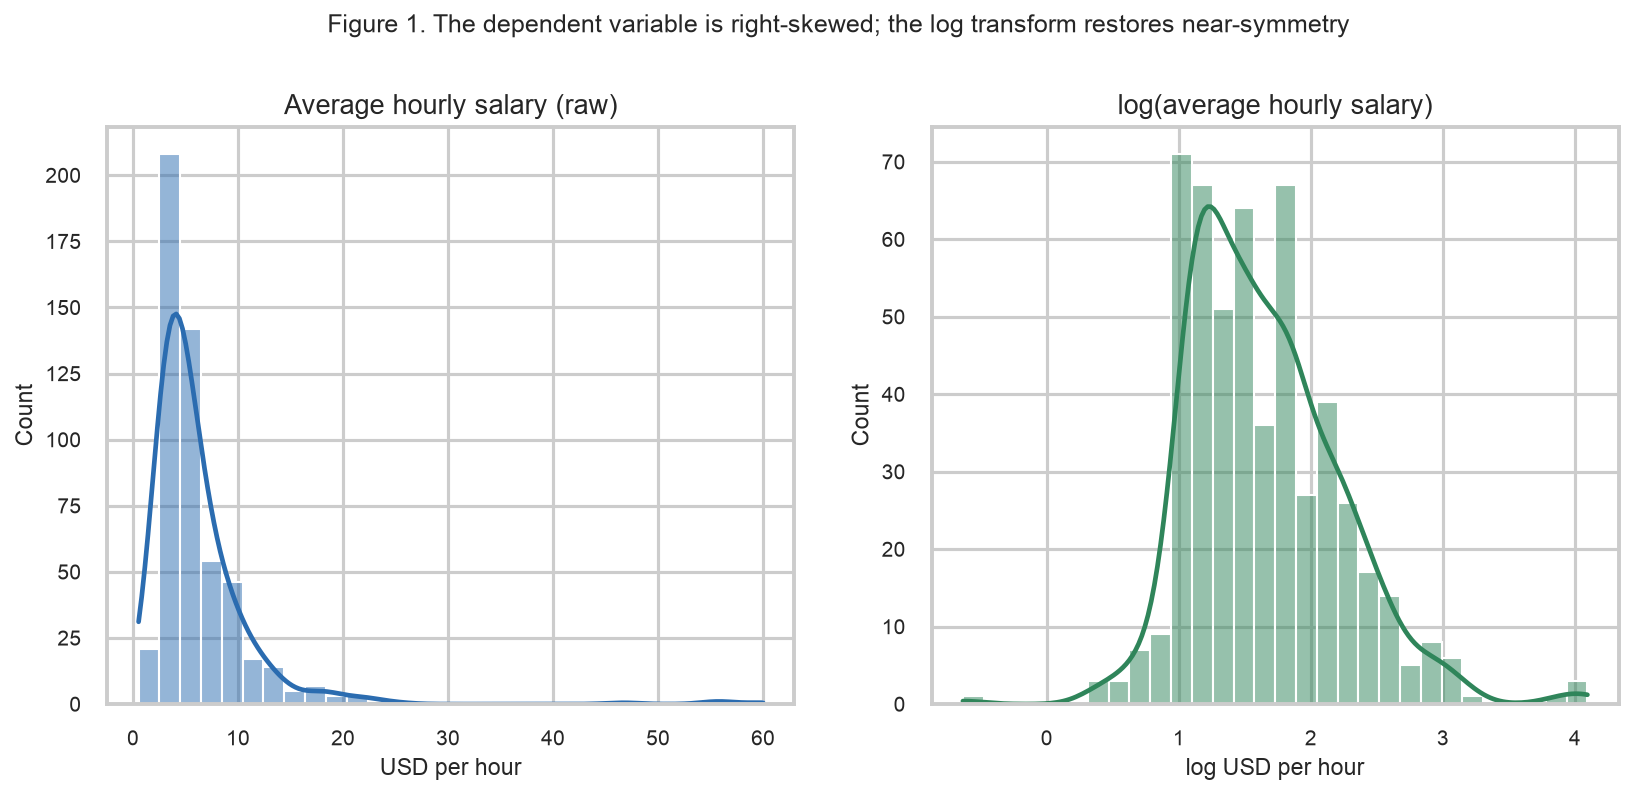

02_correlation_heatmap.png


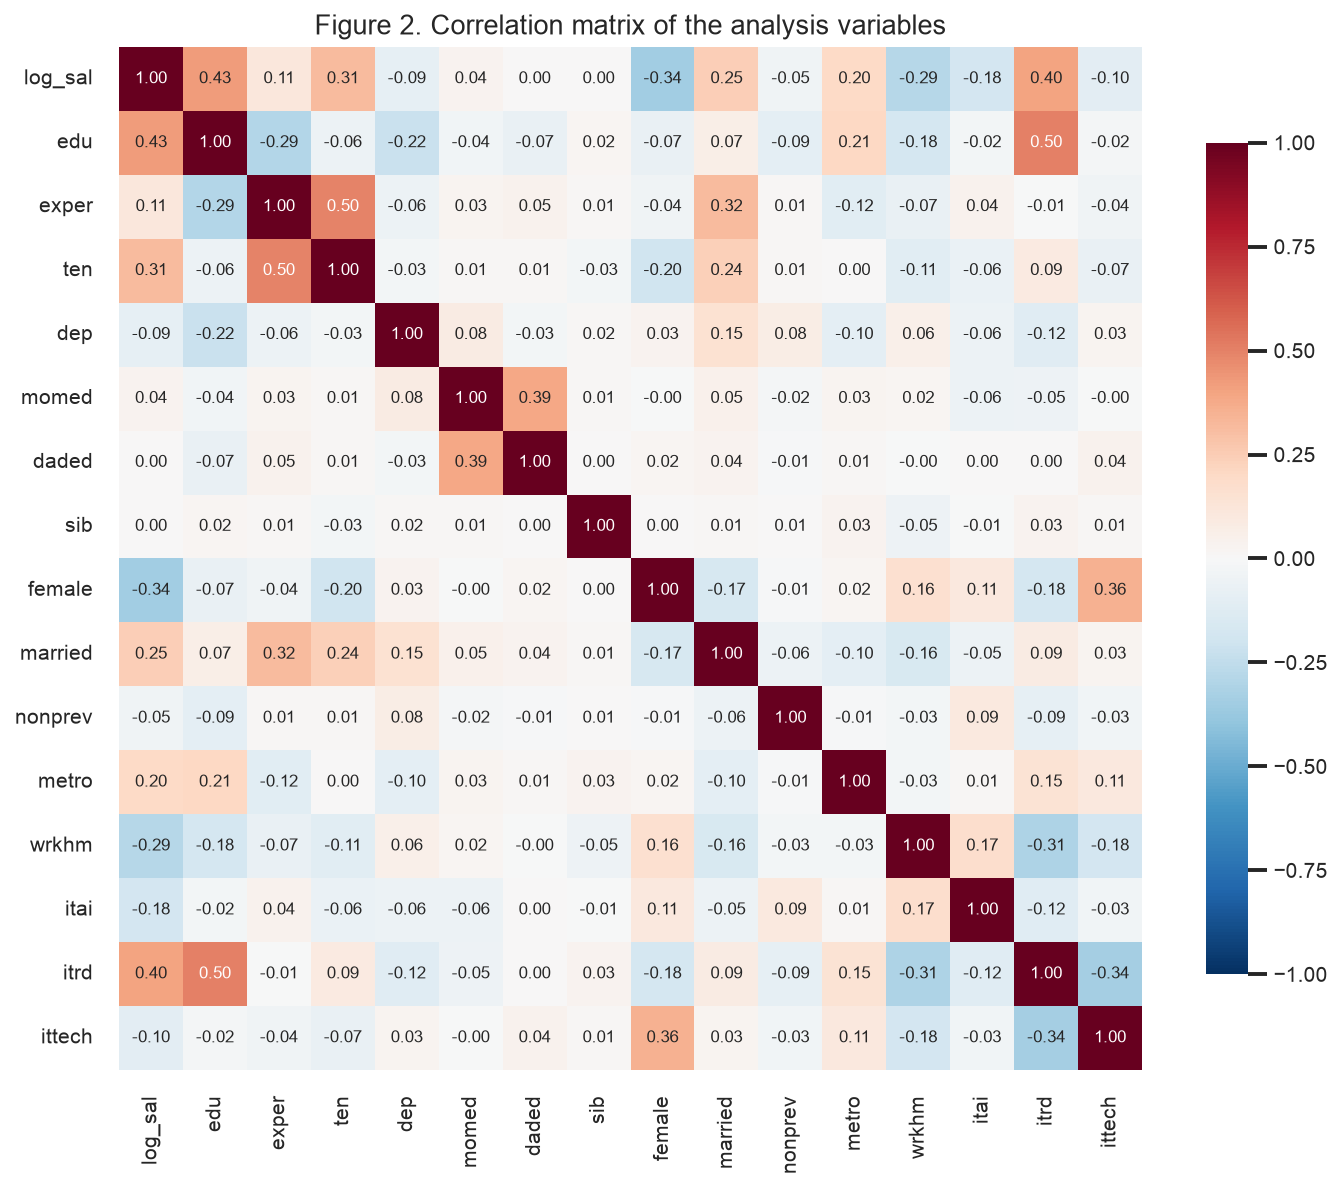

03_salary_by_function.png


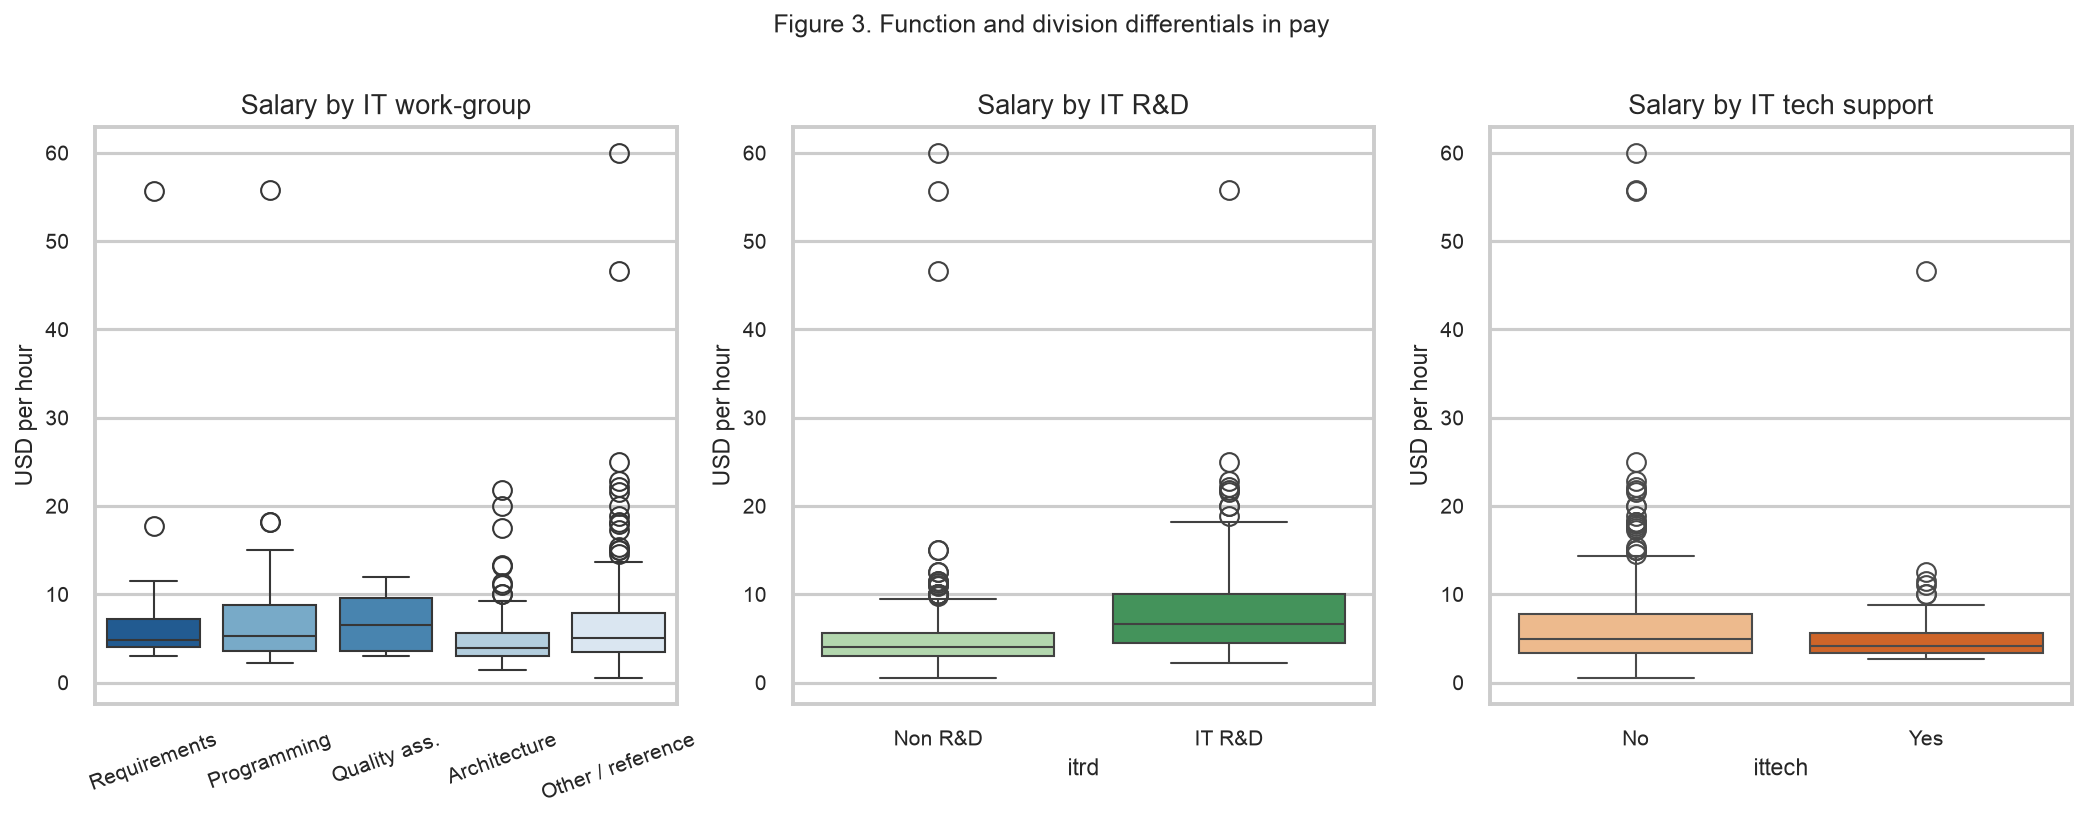

04_salary_by_region.png


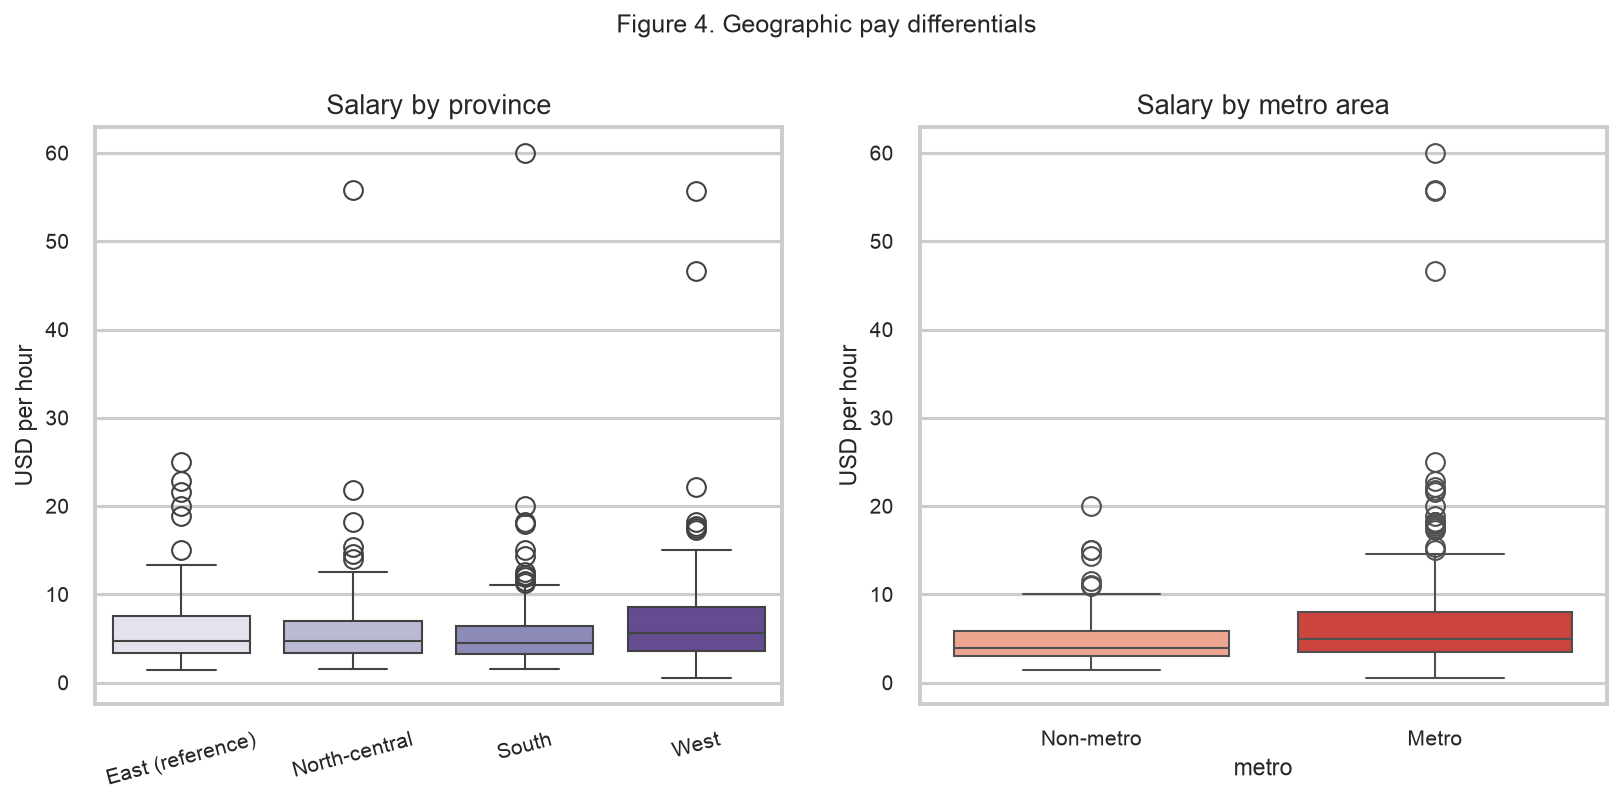

05_human_capital_profiles.png


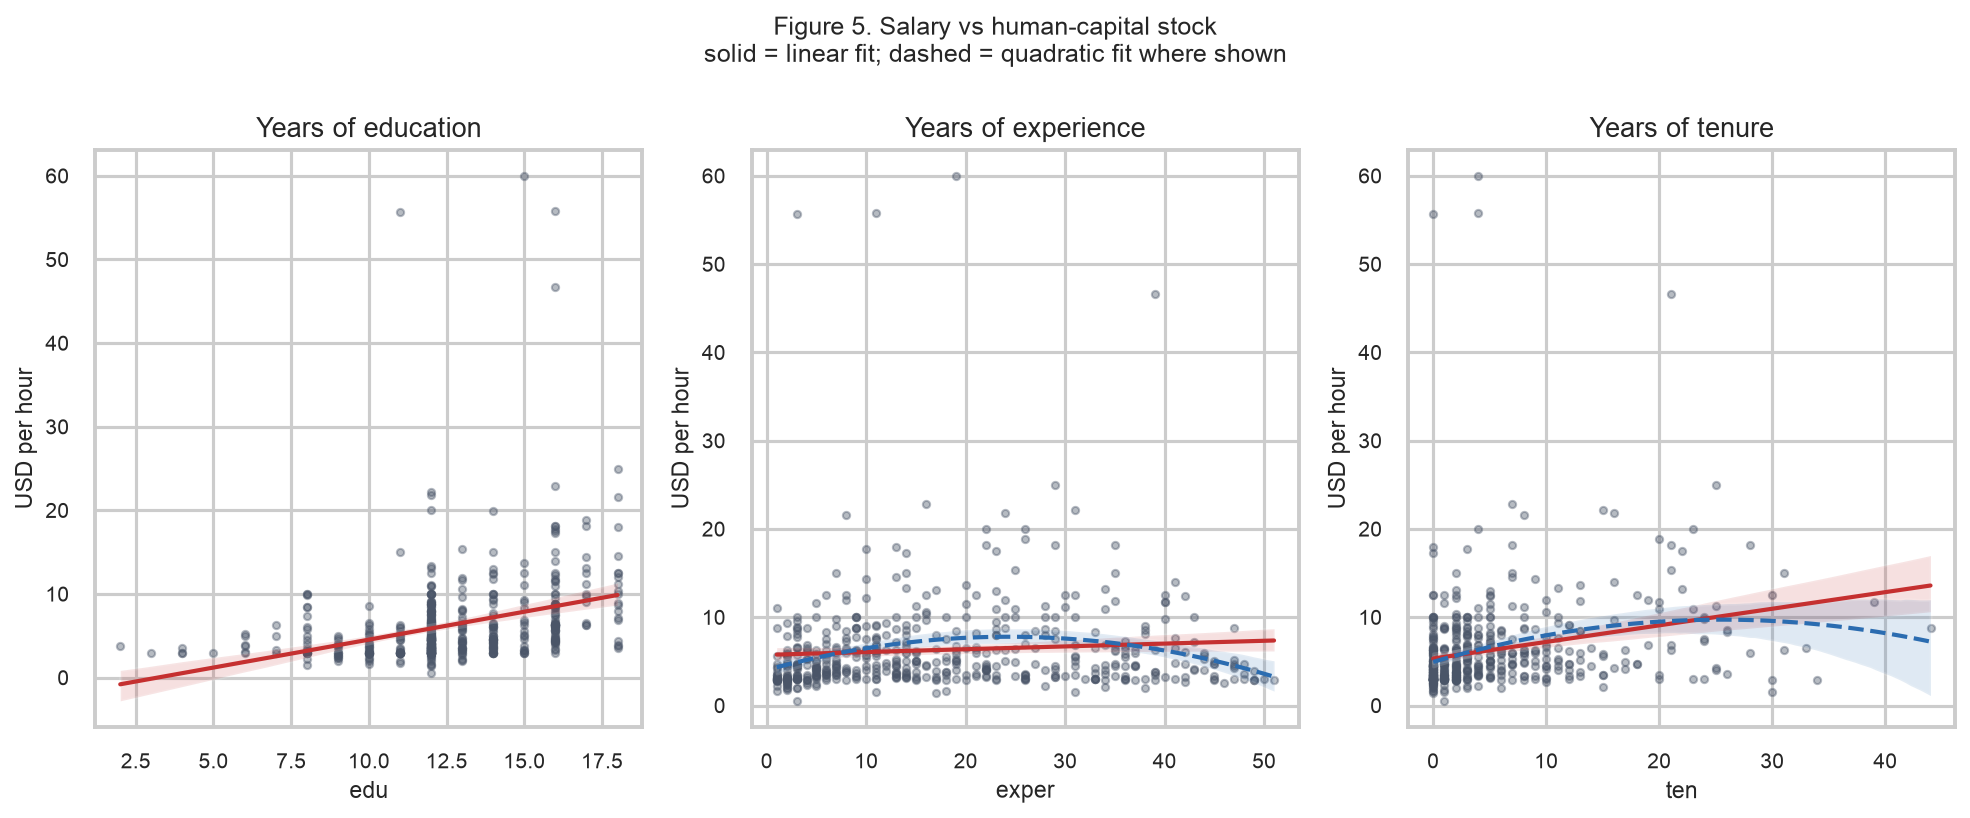

06_group_comparisons.png


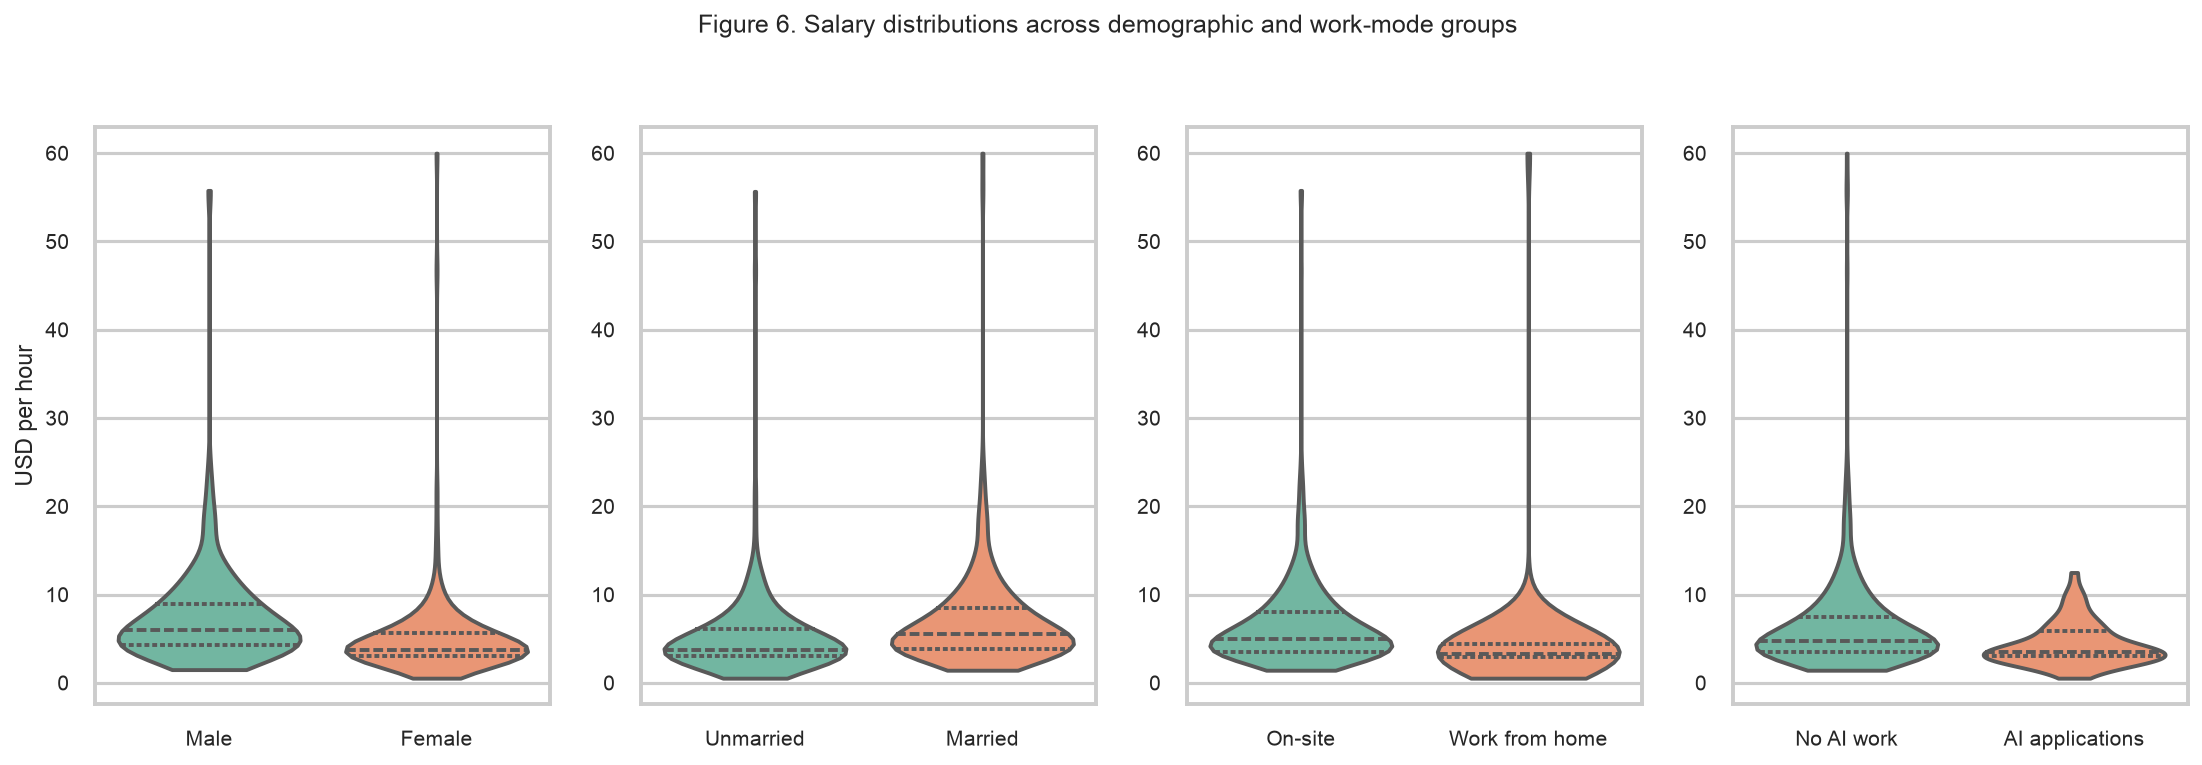

07_experience_tenure.png


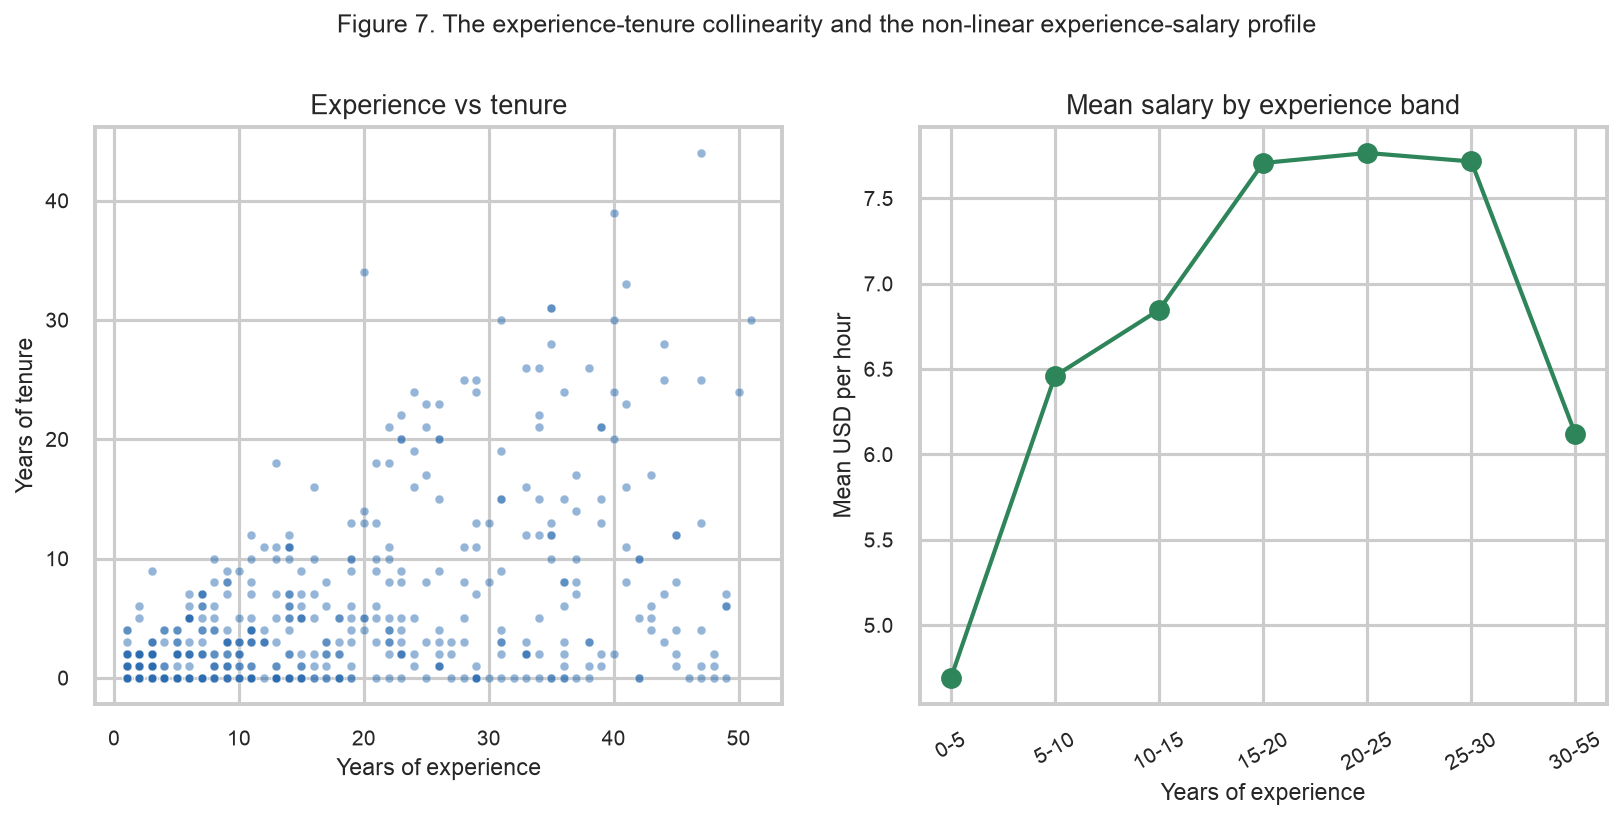

In [4]:
from IPython.display import Image, display
for p in sorted((ROOT / 'report_charts').glob('0[1-7]*.png')):
    print(p.name)
    display(Image(filename=str(p), width=900))